# 01 · Exploración de los datos

Objetivo: entender qué dicen los datos descargados en `data/raw/` antes de procesarlos.

1. Inventario: variables, periodos y huecos.
2. Subzonas **laguna** y **costa**.
3. Mapas medios.
4. Temperatura superficial (SST): series, estacionalidad, tendencia y olas de calor marinas.
5. Clorofila y física del modelo.
6. Oxígeno in situ (UPCT) e hipoxia.

In [1]:
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt

from gemelo.config import DATA_RAW, cargar_config

cfg = cargar_config()
RAW = DATA_RAW / "copernicus"
plt.rcParams.update({"figure.figsize": (11, 4), "axes.grid": True, "grid.alpha": 0.3})

sst = xr.open_dataset(RAW / "sst.nc")
chl = xr.open_dataset(RAW / "clorofila.nc")
fis = xr.merge([xr.open_dataset(RAW / f"fisica_{k}.nc") for k in ["temp", "mld", "hflux", "mflux"]],
               compat="override", join="outer")
if "depth" in fis.dims:
    fis = fis.isel(depth=0, drop=True)

# SST viene en kelvin -> pasamos a °C
sst["sst_c"] = sst["analysed_sst"] - 273.15

## 1. Inventario y huecos

In [2]:
def inventario(nombre, ds, var):
    da = ds[var]
    t = pd.DatetimeIndex(ds.time.values)
    esperado = pd.date_range(t.min().normalize(), t.max().normalize(), freq="D")
    celdas_mar = int(da.notnull().any("time").sum())
    return dict(fuente=nombre, variable=var, inicio=t.min().date(), fin=t.max().date(),
                dias=len(t), dias_faltan=len(esperado.difference(t.normalize())),
                celdas_con_dato=celdas_mar,
                pct_nan_en_celdas_mar=round(100 * float(da.where(da.notnull().any("time")).isnull().mean()), 2))

filas = [inventario("SST satélite", sst, "sst_c"), inventario("Clorofila satélite", chl, "CHL")]
filas += [inventario("Modelo física", fis, v) for v in ["thetao", "bottomT", "mlotst", "hfds", "tauuo"]]
pd.DataFrame(filas)

,fuente,variable,inicio,fin,dias,dias_faltan,celdas_con_dato,pct_nan_en_celdas_mar
0,SST satélite,sst_c,1982-01-01,2026-09-30,16344,0,65,27.78
1,Clorofila satélite,CHL,1998-01-01,2026-09-30,10500,0,1093,36.41
2,Modelo física,thetao,1998-01-01,2026-09-30,10500,0,76,42.42
3,Modelo física,bottomT,1998-01-01,2026-09-30,10500,0,76,42.42
4,Modelo física,mlotst,1998-01-01,2026-09-30,10500,0,76,42.42
5,Modelo física,hfds,1998-01-01,2026-09-30,10500,0,76,44.76
6,Modelo física,tauuo,1998-01-01,2026-09-30,10500,0,76,44.76


## 2. Subzonas

- **Laguna**: celdas dentro de La Manga. La rejilla de SST es de 0,05° (~5 km), así que solo unas pocas celdas caen claramente dentro.
- **Costa**: mar abierto al este de La Manga (lon ≥ −0,66).

Para la clorofila (1 km) y el modelo (~4 km) se usan los mismos recuadros. El modelo no tiene celdas de laguna.

In [3]:
LAGUNA = dict(latitude=slice(37.67, 37.82), longitude=slice(-0.84, -0.735))
COSTA = dict(latitude=slice(37.55, 38.0), longitude=slice(-0.66, -0.5))

def media_zona(da, zona):
    return da.sel(**zona).mean(["latitude", "longitude"])

n_lag = int(sst.sst_c.sel(**LAGUNA).isel(time=0).notnull().sum())
n_cos = int(sst.sst_c.sel(**COSTA).isel(time=0).notnull().sum())
n_chl = int(chl.CHL.sel(**LAGUNA).notnull().any("time").sum())
n_fis_lag = int(fis.thetao.sel(**LAGUNA).notnull().any("time").sum())
print(f"Celdas SST laguna: {n_lag} | costa: {n_cos}")
print(f"Celdas clorofila laguna: {n_chl}")
print(f"Celdas modelo física dentro de la laguna: {n_fis_lag}")

Celdas SST laguna: 6 | costa: 36
Celdas clorofila laguna: 91
Celdas modelo física dentro de la laguna: 0


## 3. Mapas medios

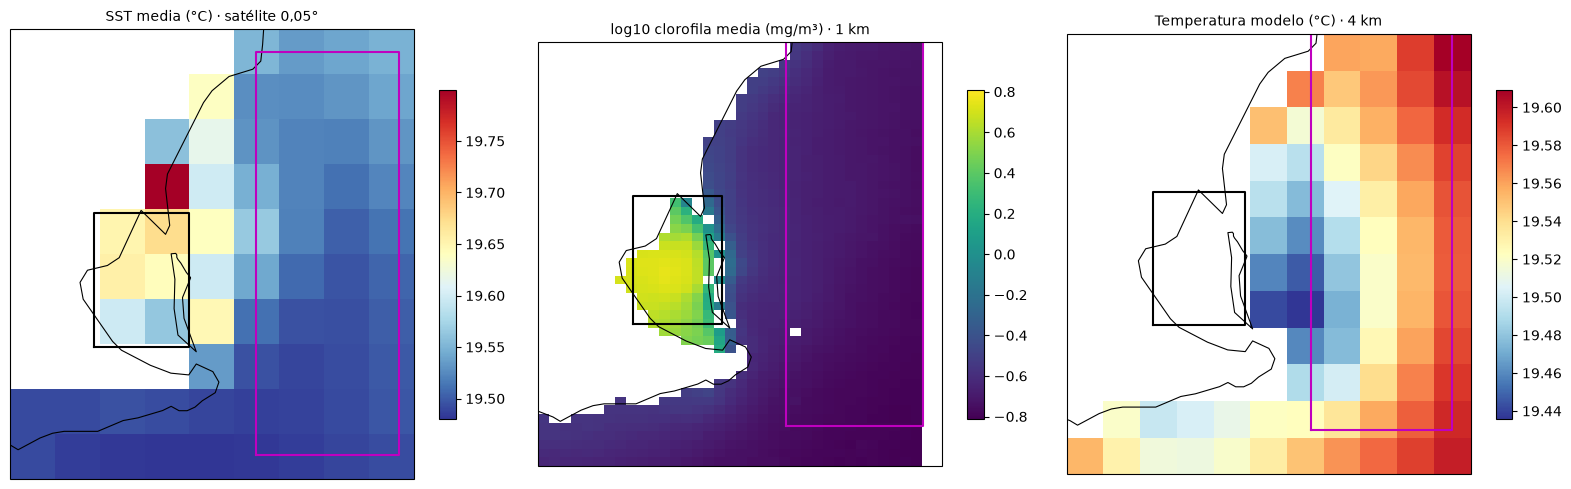

In [4]:
import cartopy.crs as ccrs
import cartopy.feature as cfeature

fig, axs = plt.subplots(1, 3, figsize=(16, 5), subplot_kw=dict(projection=ccrs.PlateCarree()))
campos = [
    (sst.sst_c.mean("time"), "SST media (°C) · satélite 0,05°", "RdYlBu_r", None),
    (np.log10(chl.CHL.mean("time")), "log10 clorofila media (mg/m³) · 1 km", "viridis", None),
    (fis.thetao.mean("time"), "Temperatura modelo (°C) · 4 km", "RdYlBu_r", None),
]
for ax, (da, titulo, cmap, _) in zip(axs, campos):
    da.plot(ax=ax, transform=ccrs.PlateCarree(), cmap=cmap, cbar_kwargs=dict(shrink=0.7, label=""))
    try:
        ax.coastlines("10m", linewidth=0.8)
    except Exception as e:  # sin conexión para descargar la costa
        print("sin línea de costa:", e)
    for z, c in [(LAGUNA, "k"), (COSTA, "m")]:
        la, lo = z["latitude"], z["longitude"]
        ax.plot([lo.start, lo.stop, lo.stop, lo.start, lo.start],
                [la.start, la.start, la.stop, la.stop, la.start], c, lw=1.5, transform=ccrs.PlateCarree())
    ax.set_title(titulo, fontsize=10)
plt.tight_layout()

## 4. SST: laguna vs. costa

Diferencia laguna − costa (°C) por mes (media 1982–2026):
time
1    -0.39
2    -0.28
3     0.09
4     0.34
5     0.33
6     0.44
7     0.69
8     0.63
9     0.38
10   -0.03
11   -0.49
12   -0.38

Máximo anual medio laguna: 28.09 °C | costa: 27.29 °C


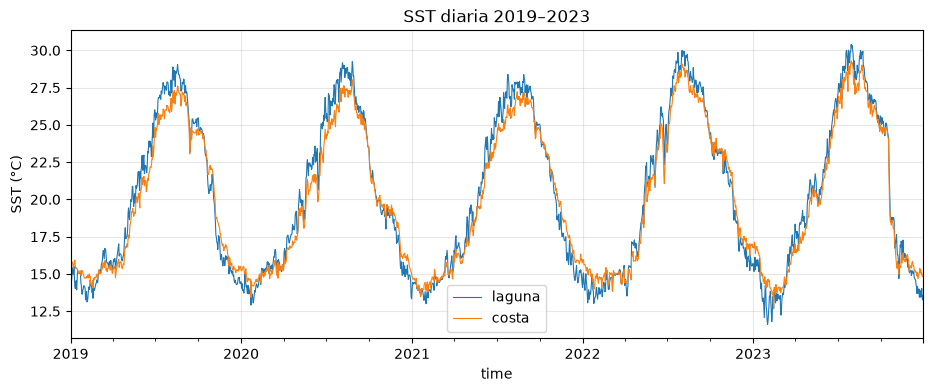

In [5]:
sst_lag = media_zona(sst.sst_c, LAGUNA).to_series()
sst_cos = media_zona(sst.sst_c, COSTA).to_series()
df = pd.DataFrame({"laguna": sst_lag, "costa": sst_cos})

fig, ax = plt.subplots()
df["2019":"2023"].plot(ax=ax, lw=0.8)
ax.set_ylabel("SST (°C)"); ax.set_title("SST diaria 2019–2023")

dif = (df.laguna - df.costa)
print("Diferencia laguna − costa (°C) por mes (media 1982–2026):")
print(dif.groupby(dif.index.month).mean().round(2).to_string())
print(f"\nMáximo anual medio laguna: {df.laguna.groupby(df.index.year).max().mean():.2f} °C | "
      f"costa: {df.costa.groupby(df.index.year).max().mean():.2f} °C")

{'laguna': '+0.31 °C/década', 'costa': '+0.27 °C/década'}


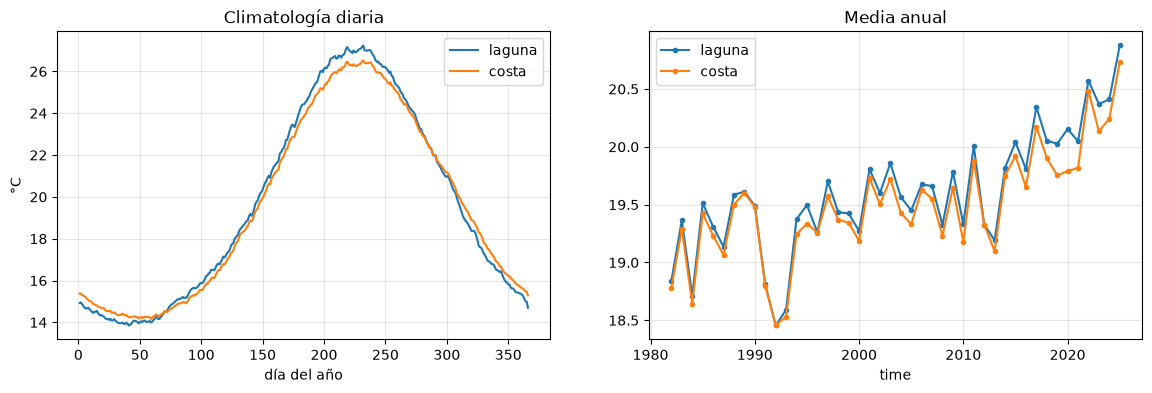

In [6]:
# Estacionalidad y tendencia
clim = df.groupby(df.index.day_of_year).mean()
anual = df.groupby(df.index.year).mean().loc[1982:2025]  # años completos
tend = {c: np.polyfit(anual.index, anual[c], 1)[0] * 10 for c in anual}

fig, axs = plt.subplots(1, 2, figsize=(14, 4))
clim.plot(ax=axs[0]); axs[0].set_xlabel("día del año"); axs[0].set_ylabel("°C"); axs[0].set_title("Climatología diaria")
anual.plot(ax=axs[1], marker="o", ms=3); axs[1].set_title("Media anual")
print({k: f"{v:+.2f} °C/década" for k, v in tend.items()})

In [7]:
# Autocorrelación: ¿cuánto 'recuerda' la SST? (clave para la línea base de persistencia)
anom = df - df.groupby(df.index.day_of_year).transform("mean")
for h in cfg["horizontes_dias"]:
    print(f"h={h:>2} d · autocorrelación anomalía laguna {anom.laguna.autocorr(h):.2f} · costa {anom.costa.autocorr(h):.2f}")

h= 1 d · autocorrelación anomalía laguna 0.93 · costa 0.93
h= 3 d · autocorrelación anomalía laguna 0.82 · costa 0.85
h= 7 d · autocorrelación anomalía laguna 0.72 · costa 0.74
h=30 d · autocorrelación anomalía laguna 0.45 · costa 0.43


### Olas de calor marinas (MHW)

Definición simplificada de Hobday et al. (2016): SST > percentil 90 de la climatología 1991–2020 del mismo día del año (ventana de ±5 días) durante ≥ 5 días seguidos.

      laguna  costa
time               
1990      23     32
2000       6      5
2010      14      7
2015      52     77
2020      71     28
2022     123    135
2023     174    166
2024      80     89
2025     150    160
% de días en MHW · 1982-2000: 3.5% · 2015-2025: 20.1% (costa)


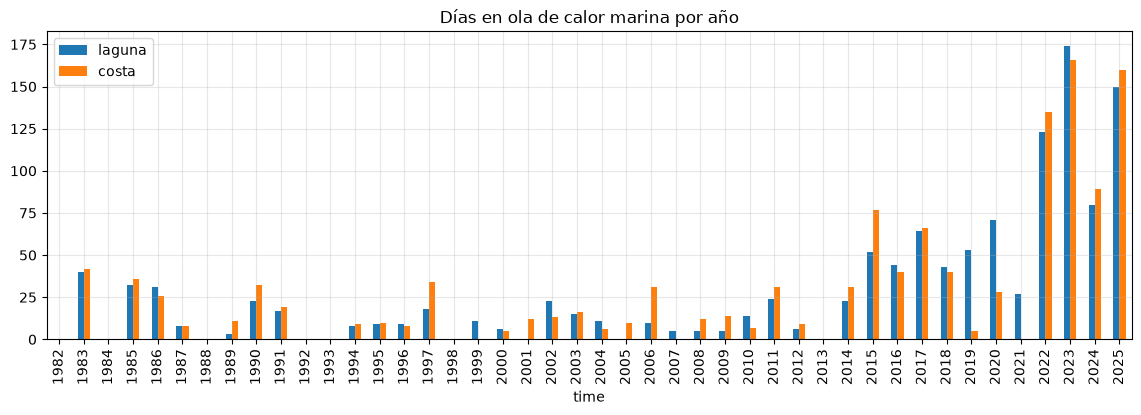

In [8]:
def mhw_dias(serie, ini="1991-01-01", fin="2020-12-31", pct=90, min_dias=5):
    ref = serie[ini:fin]
    doy = ref.index.day_of_year
    umbral = pd.Series({d: ref[np.abs(((doy - d + 183) % 366) - 183) <= 5].quantile(pct / 100)
                        for d in range(1, 367)})
    sobre = serie.values > umbral.reindex(serie.index.day_of_year).values
    # solo rachas de >= min_dias
    grupos = (pd.Series(sobre) != pd.Series(sobre).shift()).cumsum()
    largo = pd.Series(sobre).groupby(grupos).transform("size")
    return pd.Series(sobre & (largo >= min_dias).values, index=serie.index), umbral

mhw = {}
for zona in ["laguna", "costa"]:
    mhw[zona], _ = mhw_dias(df[zona].dropna())
dias_mhw = pd.DataFrame({z: s.groupby(s.index.year).sum() for z, s in mhw.items()}).loc[1982:2025]
dias_mhw.plot(kind="bar", figsize=(14, 4), title="Días en ola de calor marina por año")
print(dias_mhw.loc[[1990, 2000, 2010, 2015, 2020, 2022, 2023, 2024, 2025]].to_string())
print(f"% de días en MHW · 1982-2000: {100*mhw['costa'][:'2000'].mean():.1f}% · 2015-2025: {100*mhw['costa']['2015':'2025'].mean():.1f}% (costa)")

## 5. Clorofila y física

Clorofila laguna, media anual (mg/m³):
time
2010    3.83
2011    3.68
2012    3.67
2013    4.05
2014    3.30
2015    2.79
2016    4.44
2017    4.24
2018    4.44
2019    3.70
2020    4.05
2021    3.42
2022    3.22
2023    4.23
2024    3.65
2025    3.67
2026    3.72

SST costa modelo vs satélite · sesgo -0.17 °C · RMSE 0.52 °C · r 0.995


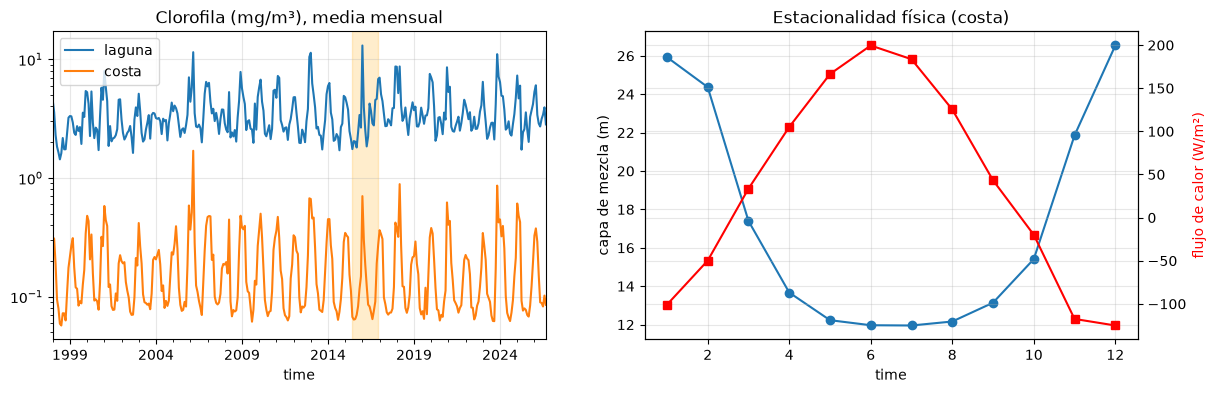

In [9]:
chl_lag = media_zona(chl.CHL, LAGUNA).to_series()
chl_cos = media_zona(chl.CHL, COSTA).to_series()
fis_cos = fis[["thetao", "bottomT", "mlotst", "hfds", "tauuo", "tauvo"]].sel(**COSTA).mean(["latitude", "longitude"]).to_dataframe()

fig, axs = plt.subplots(1, 2, figsize=(14, 4))
pd.DataFrame({"laguna": chl_lag, "costa": chl_cos}).resample("MS").mean().plot(ax=axs[0], logy=True)
axs[0].set_title("Clorofila (mg/m³), media mensual"); axs[0].axvspan("2015-06", "2016-12", color="orange", alpha=0.2)
mens = fis_cos.groupby(fis_cos.index.month).mean()
mens[["mlotst"]].plot(ax=axs[1], marker="o", legend=False); axs[1].set_ylabel("capa de mezcla (m)")
ax2 = axs[1].twinx(); mens["hfds"].plot(ax=ax2, color="r", marker="s"); ax2.set_ylabel("flujo de calor (W/m²)", color="r")
axs[1].set_title("Estacionalidad física (costa)")
print("Clorofila laguna, media anual (mg/m³):")
print(chl_lag.groupby(chl_lag.index.year).mean().round(2).loc[2010:2026].to_string())

# ¿El modelo y el satélite coinciden en la costa?
comp = pd.concat([sst_cos.rename("satélite"), fis_cos.thetao.rename("modelo")], axis=1).dropna()
print(f"\nSST costa modelo vs satélite · sesgo {(comp.modelo - comp['satélite']).mean():+.2f} °C · "
      f"RMSE {np.sqrt(((comp.modelo - comp['satélite'])**2).mean()):.2f} °C · r {comp.corr().iloc[0,1]:.3f}")

## 6. Oxígeno in situ (UPCT)

Mapas interpolados semanales (200×200 puntos, 10 niveles de 0,5 a 5 m). El "fondo" de cada punto es su nivel más profundo con dato.

Fechas descartadas por erróneas: [datetime.date(1970, 1, 1)]


Muestras por año: {2017: 34, 2018: 46, 2019: 57, 2020: 63, 2021: 55, 2022: 52, 2023: 52, 2024: 28}
Intervalo entre campañas (días): {'50%': 7.0, 'max': 35.0}
Rango de valores O2 (mg/L): 0.0 → 16.773468017578125



Campañas con > 5 % del fondo en hipoxia:
            o2_sup_media  o2_fondo_media  o2_fondo_min  pct_area_hipoxia
time                                                                    
2017-08-30          5.86            4.39          2.65              8.44
2017-09-06          5.42            4.20          2.29             34.61
2017-09-11          5.59            4.13          2.91             34.02
2018-09-13          5.11            4.50          3.68              7.64
2019-08-29          5.23            4.99          2.50              8.40
2019-09-18          7.93            5.64          2.28              9.78
2019-09-19         11.46            5.92          1.16             31.00
2019-09-26          6.23            2.18          0.00             70.38
2019-09-27          5.78            2.05          0.00             72.01
2019-09-28          5.98            2.34          0.00             69.14
2019-10-03          5.00            2.12          0.00             65.65
2019-10-1

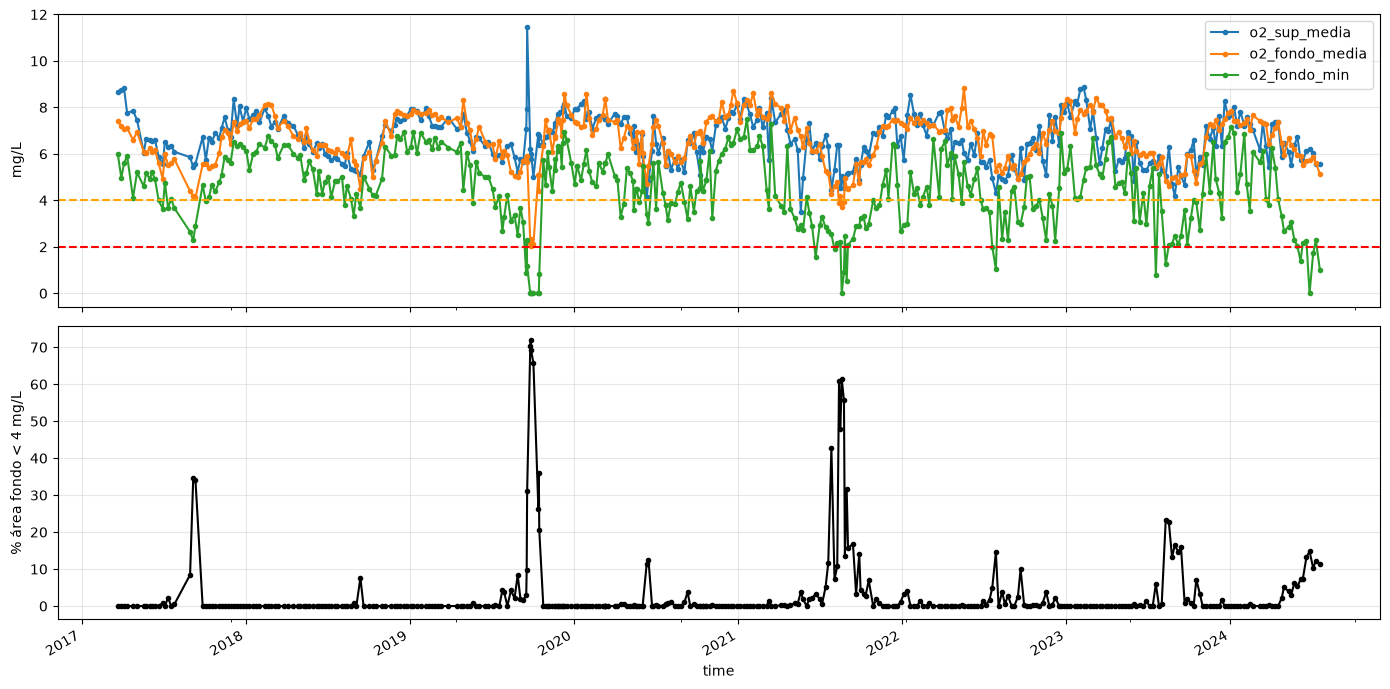

In [10]:
o2 = xr.open_dataset(DATA_RAW / "upct" / "oxigeno_l2.nc", decode_times=False)
fechas = pd.to_datetime(o2.time.values, unit="D", origin="1970-01-01")
validas = fechas >= "2000-01-01"
print("Fechas descartadas por erróneas:", list(fechas[~validas].date))
o2 = o2.isel(time=np.where(validas)[0]).assign_coords(time=fechas[validas]).sortby("time")
O2 = o2.Oxigeno

# nivel más profundo con dato en cada punto (se toma la máscara de todo el periodo)
tiene = O2.notnull().any("time")
idx_fondo = (tiene * xr.DataArray(np.arange(O2.sizes["level"]), dims="level")).where(tiene).max("level")
fondo = O2.isel(level=idx_fondo.fillna(0).astype(int)).where(idx_fondo.notnull())

serie = pd.DataFrame({
    "o2_sup_media": O2.isel(level=0).mean(["latitude", "longitude"]).to_series(),
    "o2_fondo_media": fondo.mean(["latitude", "longitude"]).to_series(),
    "o2_fondo_min": fondo.min(["latitude", "longitude"]).to_series(),
    "pct_area_hipoxia": (100 * (fondo < cfg["umbrales"]["hipoxia_mg_l"]).sum(["latitude", "longitude"])
                         / fondo.notnull().sum(["latitude", "longitude"])).to_series(),
})
print("Muestras por año:", serie.groupby(serie.index.year).size().to_dict())
print("Intervalo entre campañas (días):", serie.index.to_series().diff().dt.days.describe()[["50%", "max"]].to_dict())
print("Rango de valores O2 (mg/L):", float(O2.min()), "→", float(O2.max()))

fig, axs = plt.subplots(2, 1, figsize=(14, 7), sharex=True)
serie[["o2_sup_media", "o2_fondo_media", "o2_fondo_min"]].plot(ax=axs[0], marker=".")
axs[0].axhline(4, c="orange", ls="--"); axs[0].axhline(2, c="r", ls="--"); axs[0].set_ylabel("mg/L")
serie.pct_area_hipoxia.plot(ax=axs[1], kind="line", marker=".", c="k"); axs[1].set_ylabel("% área fondo < 4 mg/L")
plt.tight_layout()

print("\nCampañas con > 5 % del fondo en hipoxia:")
print(serie[serie.pct_area_hipoxia > 5].round(2).to_string())

Correlación SST laguna – O2 fondo medio: -0.77


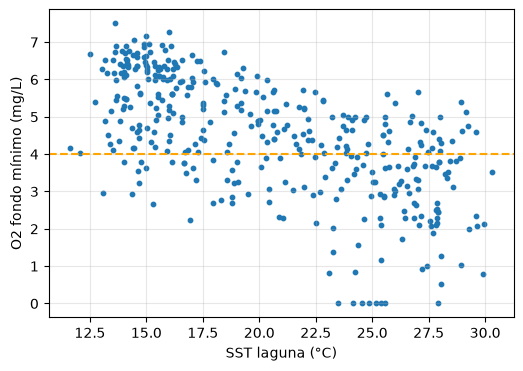

In [11]:
# Relación con la temperatura de la laguna (SST satélite el mismo día)
rel = serie.join(sst_lag.rename("sst_laguna"), how="inner")
fig, ax = plt.subplots(figsize=(6, 4))
ax.scatter(rel.sst_laguna, rel.o2_fondo_min, s=10)
ax.axhline(4, c="orange", ls="--"); ax.set_xlabel("SST laguna (°C)"); ax.set_ylabel("O2 fondo mínimo (mg/L)")
print(f"Correlación SST laguna – O2 fondo medio: {rel[['sst_laguna','o2_fondo_media']].corr().iloc[0,1]:.2f}")